<a href="https://colab.research.google.com/github/raditya12/MachineLearning/blob/master/MachineLearnJS4TugasPraktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas Praktikum**

**1. Tugas K-Means**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [ ]:
##load data
from google.colab import files


df = pd.read_csv('/content/Mall_Customers.csv')

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [ ]:
##fitur clustering
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [ ]:
##standardisasi fitur
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

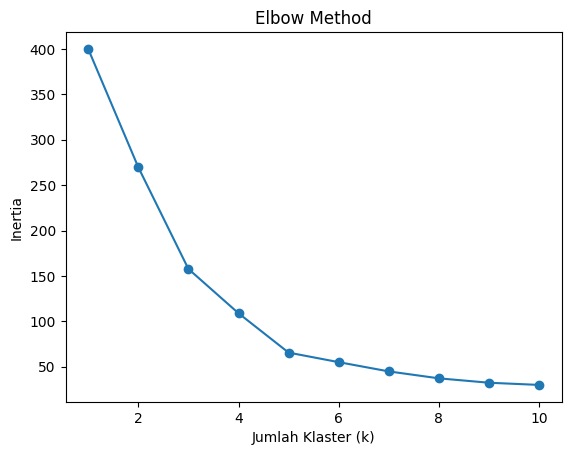

In [ ]:
##menentukan jumlah cluster dengan elbow method
inertia = []

K = range(1, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

plt.plot(K, inertia, marker='o')

plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')

plt.show()

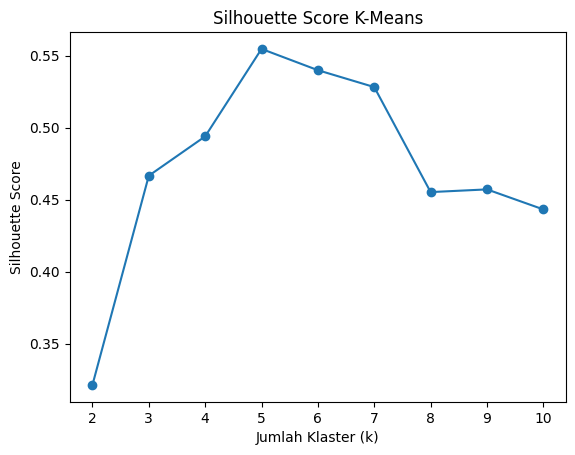

In [ ]:
##silhouette score
silhouette_scores = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

plt.plot(K, silhouette_scores, marker='o')

plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score K-Means')

plt.show()

In [ ]:
##mwmbuat model k-means
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


In [ ]:
##lihat jumlah anggota tiap cluster
df['Cluster'].value_counts().sort_index()

,count
Cluster,
0,81
1,39
2,22
3,35
4,23


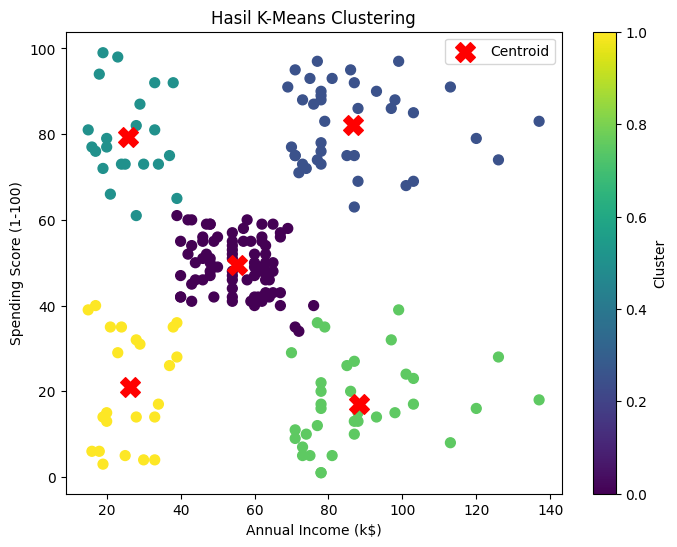

In [ ]:
##visualisasi hasil
plt.figure(figsize=(8, 6))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

# Mengembalikan centroid ke skala asli
centroids = scaler.inverse_transform(
    kmeans.cluster_centers_
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c='red',
    marker='X',
    s=200,
    label='Centroid'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Hasil K-Means Clustering')

plt.legend()
plt.colorbar(label='Cluster')

plt.show()

# **TUGAS 2 - DBSCAN**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn import metrics

In [ ]:
##membuat dataset make_moons
X, labels_true = make_moons(
    n_samples=1000,
    noise=0.05,
    random_state=42
)

X = StandardScaler().fit_transform(X)

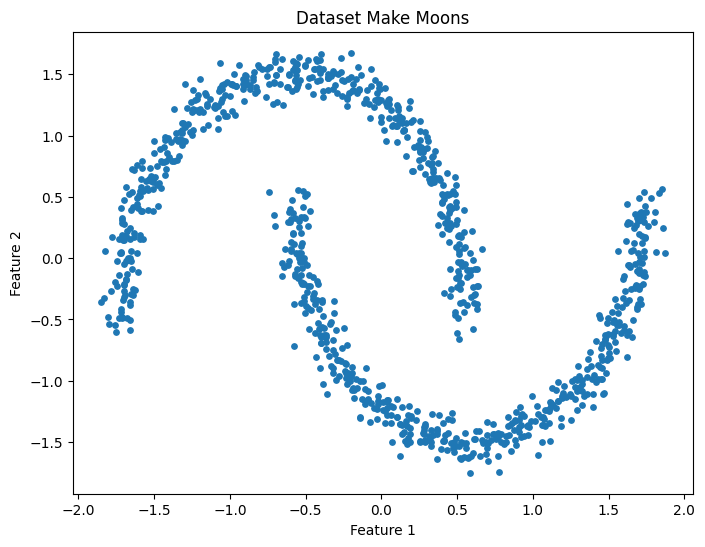

In [ ]:
##visuaslisasi
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    s=15
)

plt.title('Dataset Make Moons')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.show()

In [ ]:
##membuat model DBSCAN
db = DBSCAN(
    eps=0.2,
    min_samples=5
).fit(X)

labels = db.labels_

In [ ]:
##membuat jumlah cluster dan noise
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)

n_noise_ = list(labels).count(-1)

print("Jumlah klaster:", n_clusters_)
print("Jumlah noise:", n_noise_)

Jumlah klaster: 2
Jumlah noise: 0


In [ ]:
##evaluasi
print(
    f"Homogeneity: "
    f"{metrics.homogeneity_score(labels_true, labels):.3f}"
)

print(
    f"Completeness: "
    f"{metrics.completeness_score(labels_true, labels):.3f}"
)

print(
    f"V-measure: "
    f"{metrics.v_measure_score(labels_true, labels):.3f}"
)

print(
    f"Adjusted Rand Index: "
    f"{metrics.adjusted_rand_score(labels_true, labels):.3f}"
)

print(
    f"Adjusted Mutual Information: "
    f"{metrics.adjusted_mutual_info_score(labels_true, labels):.3f}"
)

print(
    f"Silhouette Coefficient: "
    f"{metrics.silhouette_score(X, labels):.3f}"
)

Homogeneity: 1.000
Completeness: 1.000
V-measure: 1.000
Adjusted Rand Index: 1.000
Adjusted Mutual Information: 1.000
Silhouette Coefficient: 0.391


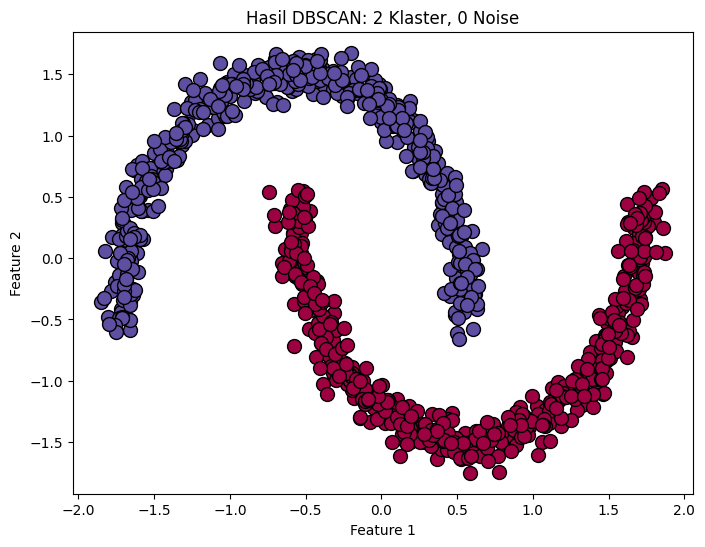

In [ ]:
##visualisasi hasil
# Visualisasi Hasil Klasterisasi

unique_labels = set(labels)

core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

colors = [
    plt.cm.Spectral(each)
    for each in np.linspace(0, 1, len(unique_labels))
]

plt.figure(figsize=(8, 6))

for k, col in zip(unique_labels, colors):

    if k == -1:
        # Warna hitam untuk noise
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    # Core points
    xy = X[class_member_mask & core_samples_mask]

    plt.plot(
        xy[:, 0],
        xy[:, 1],
        'o',
        markerfacecolor=tuple(col),
        markeredgecolor='k',
        markersize=10
    )

    # Non-core points dan noise
    xy = X[class_member_mask & ~core_samples_mask]

    plt.plot(
        xy[:, 0],
        xy[:, 1],
        'o',
        markerfacecolor=tuple(col),
        markeredgecolor='k',
        markersize=4
    )

plt.title(
    f'Hasil DBSCAN: {n_clusters_} Klaster, {n_noise_} Noise'
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.show()


In [ ]:
## eksperimen parameter DBSCAN

eps_values = [0.05, 0.1, 0.3, 0.5]

min_samples_values = [3, 10, 20]

In [ ]:
hasil = []

for eps in eps_values:
    for min_samples in min_samples_values:

        db_exp = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels_exp = db_exp.fit_predict(X)

        # Jumlah klaster dan noise
        n_clusters = len(set(labels_exp)) - (
            1 if -1 in labels_exp else 0
        )

        n_noise = list(labels_exp).count(-1)

        # Evaluasi
        homogeneity = metrics.homogeneity_score(
            labels_true, labels_exp
        )

        completeness = metrics.completeness_score(
            labels_true, labels_exp
        )

        v_measure = metrics.v_measure_score(
            labels_true, labels_exp
        )

        ari = metrics.adjusted_rand_score(
            labels_true, labels_exp
        )

        ami = metrics.adjusted_mutual_info_score(
            labels_true, labels_exp
        )

        # Silhouette hanya untuk minimal 2 klaster
        # Noise tidak dimasukkan dalam perhitungan
        mask = labels_exp != -1

        if n_clusters >= 2 and mask.sum() > n_clusters:
            silhouette = metrics.silhouette_score(
                X[mask],
                labels_exp[mask]
            )
        else:
            silhouette = np.nan

        hasil.append({
            'eps': eps,
            'min_samples': min_samples,
            'Jumlah Klaster': n_clusters,
            'Jumlah Noise': n_noise,
            'Homogeneity': homogeneity,
            'Completeness': completeness,
            'V-measure': v_measure,
            'ARI': ari,
            'AMI': ami,
            'Silhouette': silhouette
        })

df_hasil = pd.DataFrame(hasil)

display(df_hasil.round(3))

,eps,min_samples,Jumlah Klaster,Jumlah Noise,Homogeneity,Completeness,V-measure,ARI,AMI,Silhouette
0,0.05,3,69,186,0.816,0.153,0.257,0.030,0.244,0.349
1,0.05,10,3,970,0.031,0.127,0.049,0.002,0.046,0.881
2,0.05,20,0,1000,0.000,1.000,0.000,0.000,0.000,NaN
3,0.10,3,2,14,0.986,0.903,0.943,0.972,0.943,0.394
4,0.10,10,7,57,0.943,0.410,0.571,0.523,0.570,0.210
5,0.10,20,6,850,0.154,0.155,0.155,0.017,0.151,0.787
6,0.30,3,2,0,1.000,1.000,1.000,1.000,1.000,0.391
7,0.30,10,2,0,1.000,1.000,1.000,1.000,1.000,0.391
8,0.30,20,2,0,1.000,1.000,1.000,1.000,1.000,0.391
9,0.50,3,2,0,1.000,1.000,1.000,1.000,1.000,0.391


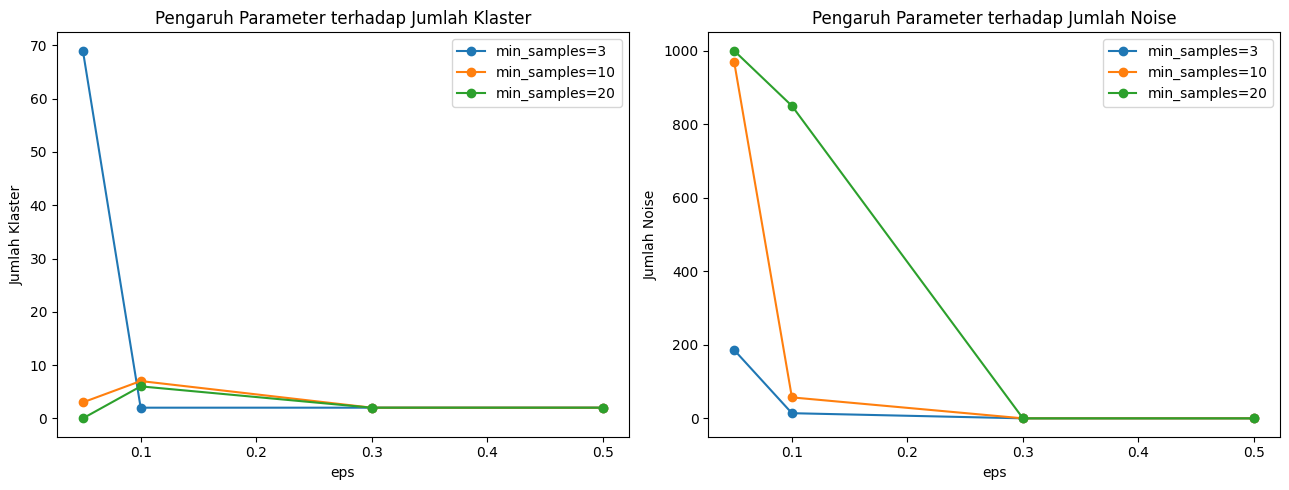

In [ ]:
##visualisasi perbandingan eksperimen
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for min_samples in min_samples_values:

    data = df_hasil[
        df_hasil['min_samples'] == min_samples
    ]

    axes[0].plot(
        data['eps'],
        data['Jumlah Klaster'],
        marker='o',
        label=f'min_samples={min_samples}'
    )

    axes[1].plot(
        data['eps'],
        data['Jumlah Noise'],
        marker='o',
        label=f'min_samples={min_samples}'
    )

axes[0].set_title('Pengaruh Parameter terhadap Jumlah Klaster')
axes[0].set_xlabel('eps')
axes[0].set_ylabel('Jumlah Klaster')
axes[0].legend()

axes[1].set_title('Pengaruh Parameter terhadap Jumlah Noise')
axes[1].set_xlabel('eps')
axes[1].set_ylabel('Jumlah Noise')
axes[1].legend()

plt.tight_layout()
plt.show()